# Notebook 03: Modelos de regresión lineal, interpretación y conclusiones
**Proyecto final: emisiones de CO₂ per cápita (Our World in Data)** · Responsables: Ana (modelos) y todo el grupo (interpretación)

Este notebook usa los datos limpios del notebook 01 (`../data/co2_limpio_2019.csv`).

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

AZUL = "#2a6fbb"      # color principal de datos
GRIS = "#8a8f98"      # contexto / comparaciones
ROJO = "#c8452f"      # resaltar un caso o la recta del modelo
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10,
})

ANIO = 2019   # mismo año de análisis que el notebook 01

limpio = pd.read_csv("../data/co2_limpio_2019.csv")    # salida del notebook 01
print(f"Países en el modelo: {limpio.shape[0]} (año {ANIO})")

Países en el modelo: 164 (año 2019)


---
# Parte 3. Modelos de regresión lineal
*Responsable: Ana*

Se ajustan tres modelos, de menor a mayor complejidad, y se comparan:

| Modelo | Ecuación | Idea |
|---|---|---|
| 1. Simple | CO₂ pc = b₀ + b₁·Energía pc | ¿Solo la energía explica las emisiones? |
| 2. Múltiple | CO₂ pc = b₀ + b₁·Energía pc + b₂·PIB pc | ¿El ingreso aporta algo más? |
| 3. Log-log | ln(CO₂ pc) = b₀ + b₁·ln(Energía pc) + b₂·ln(PIB pc) | Corrige el sesgo y la dispersión creciente |

## 3.1 Preparación: partición entrenamiento / prueba

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

y = limpio["co2_per_capita"]
X = limpio[["energy_per_capita", "gdp_per_capita"]]

# 80 % para entrenar y 20 % para evaluar con datos que el modelo no vio
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Entrenamiento: {len(X_tr)} países | Prueba: {len(X_te)} países")

resultados = {}
def evaluar(nombre, y_real, y_pred):
    # Métricas siempre en toneladas por persona, para poder comparar los tres modelos
    y_real, y_pred = np.asarray(y_real), np.asarray(y_pred)
    resultados[nombre] = {
        "R² (prueba)": r2_score(y_real, y_pred),
        "RMSE (t/persona)": np.sqrt(mean_squared_error(y_real, y_pred)),
        "MAE (t/persona)": mean_absolute_error(y_real, y_pred),
        "Error relativo mediano (%)": np.median(np.abs(y_pred / y_real - 1)) * 100,
    }

Entrenamiento: 131 países | Prueba: 33 países


## 3.2 Modelo 1: regresión lineal simple

In [3]:
m1 = LinearRegression().fit(X_tr[["energy_per_capita"]], y_tr)
pred1 = m1.predict(X_te[["energy_per_capita"]])
evaluar("1. Simple (energía)", y_te, pred1)

b0, b1 = m1.intercept_, m1.coef_[0]
print(f"CO₂ pc = {b0:.3f} + {b1:.6f} · Energía pc")
print(f"Por cada 1 000 kWh adicionales por persona, el CO₂ per cápita sube {b1*1000:.3f} t")
print(f"R² entrenamiento = {m1.score(X_tr[['energy_per_capita']], y_tr):.3f} | R² prueba = {r2_score(y_te, pred1):.3f}")

CO₂ pc = 0.832 + 0.000148 · Energía pc
Por cada 1 000 kWh adicionales por persona, el CO₂ per cápita sube 0.148 t
R² entrenamiento = 0.785 | R² prueba = 0.594


C:\Users\ANA\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


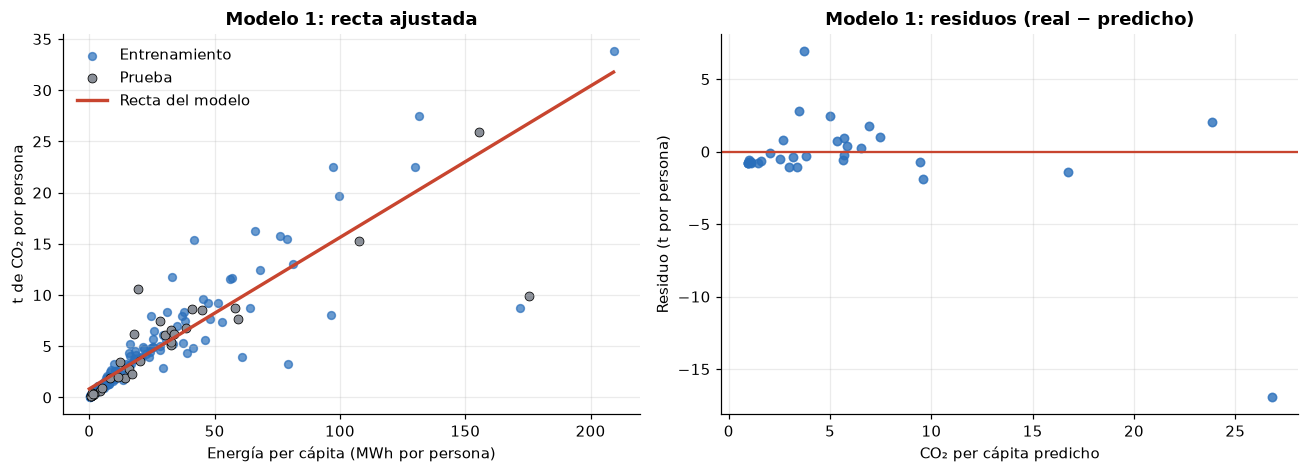

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

xs = np.linspace(0, limpio["energy_per_capita"].max(), 100).reshape(-1, 1)
axes[0].scatter(X_tr["energy_per_capita"] / 1000, y_tr, s=26, color=AZUL, alpha=0.7, label="Entrenamiento")
axes[0].scatter(X_te["energy_per_capita"] / 1000, y_te, s=34, color=GRIS, edgecolor="black", lw=0.5, label="Prueba")
axes[0].plot(xs / 1000, m1.predict(xs), color=ROJO, lw=2.2, label="Recta del modelo")
axes[0].set_title("Modelo 1: recta ajustada")
axes[0].set_xlabel("Energía per cápita (MWh por persona)"); axes[0].set_ylabel("t de CO₂ por persona")
axes[0].legend(frameon=False)

resid = y_te - pred1
axes[1].scatter(pred1, resid, s=30, color=AZUL, alpha=0.8)
axes[1].axhline(0, color=ROJO, lw=1.5)
axes[1].set_title("Modelo 1: residuos (real − predicho)")
axes[1].set_xlabel("CO₂ per cápita predicho"); axes[1].set_ylabel("Residuo (t por persona)")
plt.tight_layout(); plt.show()

**Diagnóstico:** la recta sigue bien la tendencia de la gran mayoría de países (los de consumo bajo y medio). Los errores grandes aparecen en la zona alta: en el gráfico de residuos hay un caso extremo con un residuo cercano a −17 t por persona. Más abajo se identifica ese país y se mide cuánto pesa en las métricas.